In [8]:
import matplotlib.pyplot as plt
import numpy as np

# for BLOB
from scipy.stats import multivariate_normal


# Set default plotting parameters
plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [13]:
center_lat = 0.0  # Center latitude of the Gaussian blob
center_lon = 0.0  # Center longitude of the Gaussian blob
sigma_lat = 20.0  # Standard deviation in latitude
sigma_lon = 30.0  # Standard deviation in longitude

def make_shape(
        lats,
        lons,
    ) -> np.ndarray:
        """
        Generates a spatial blob of parameters on the grid in shape of a 2D Gauss, given positional and
        spatial shape parameters. Returns a mask of the same shape as the grid, where values above 0.5
        indicate presence of the blob.
        """
        # Handle longitude periodicity to ensure continuity at the dateline (global dataset!)
        extended_lons = np.concatenate([lons - 360, lons, lons + 360])

        # Create grids
        lat_grid, extended_lon_grid = np.meshgrid(lats, extended_lons, indexing="ij")
        pos_extended = np.dstack((lat_grid, extended_lon_grid))

        # Calculate Gaussian Shape
        cov = np.array([[sigma_lat**2, 0], [0, sigma_lon**2]])
        # - create multivariate normal distribution
        rv = multivariate_normal(mean=[center_lat, center_lon], cov=cov)
        # - compute probability density function (PDF) over the extended grid
        extended_shape = rv.pdf(pos_extended)
        shape_normalized = extended_shape / np.max(extended_shape)

        # add up contributions from periodic longitudes, shape_contribution is of shape (lat_size, lon_size)
        shape_contribution = np.sum(
            shape_normalized.reshape(len(lats), 3, len(lons)).transpose(1, 0, 2),
            axis=0,
        ).reshape(len(lats), len(lons))
        # create mask where shape_contribution is above 0.5
        shape_mask = np.where(shape_contribution > 0.5, True, False)

        return shape_mask

lats = np.linspace(-90, 90, 180)  # Example latitude grid
lons = np.linspace(-180, 180, 360)  # Example longitude grid
shape_mask = make_shape(lats, lons)

print("Shape mask generated with dimensions:", shape_mask.shape)

Shape mask generated with dimensions: (180, 360)


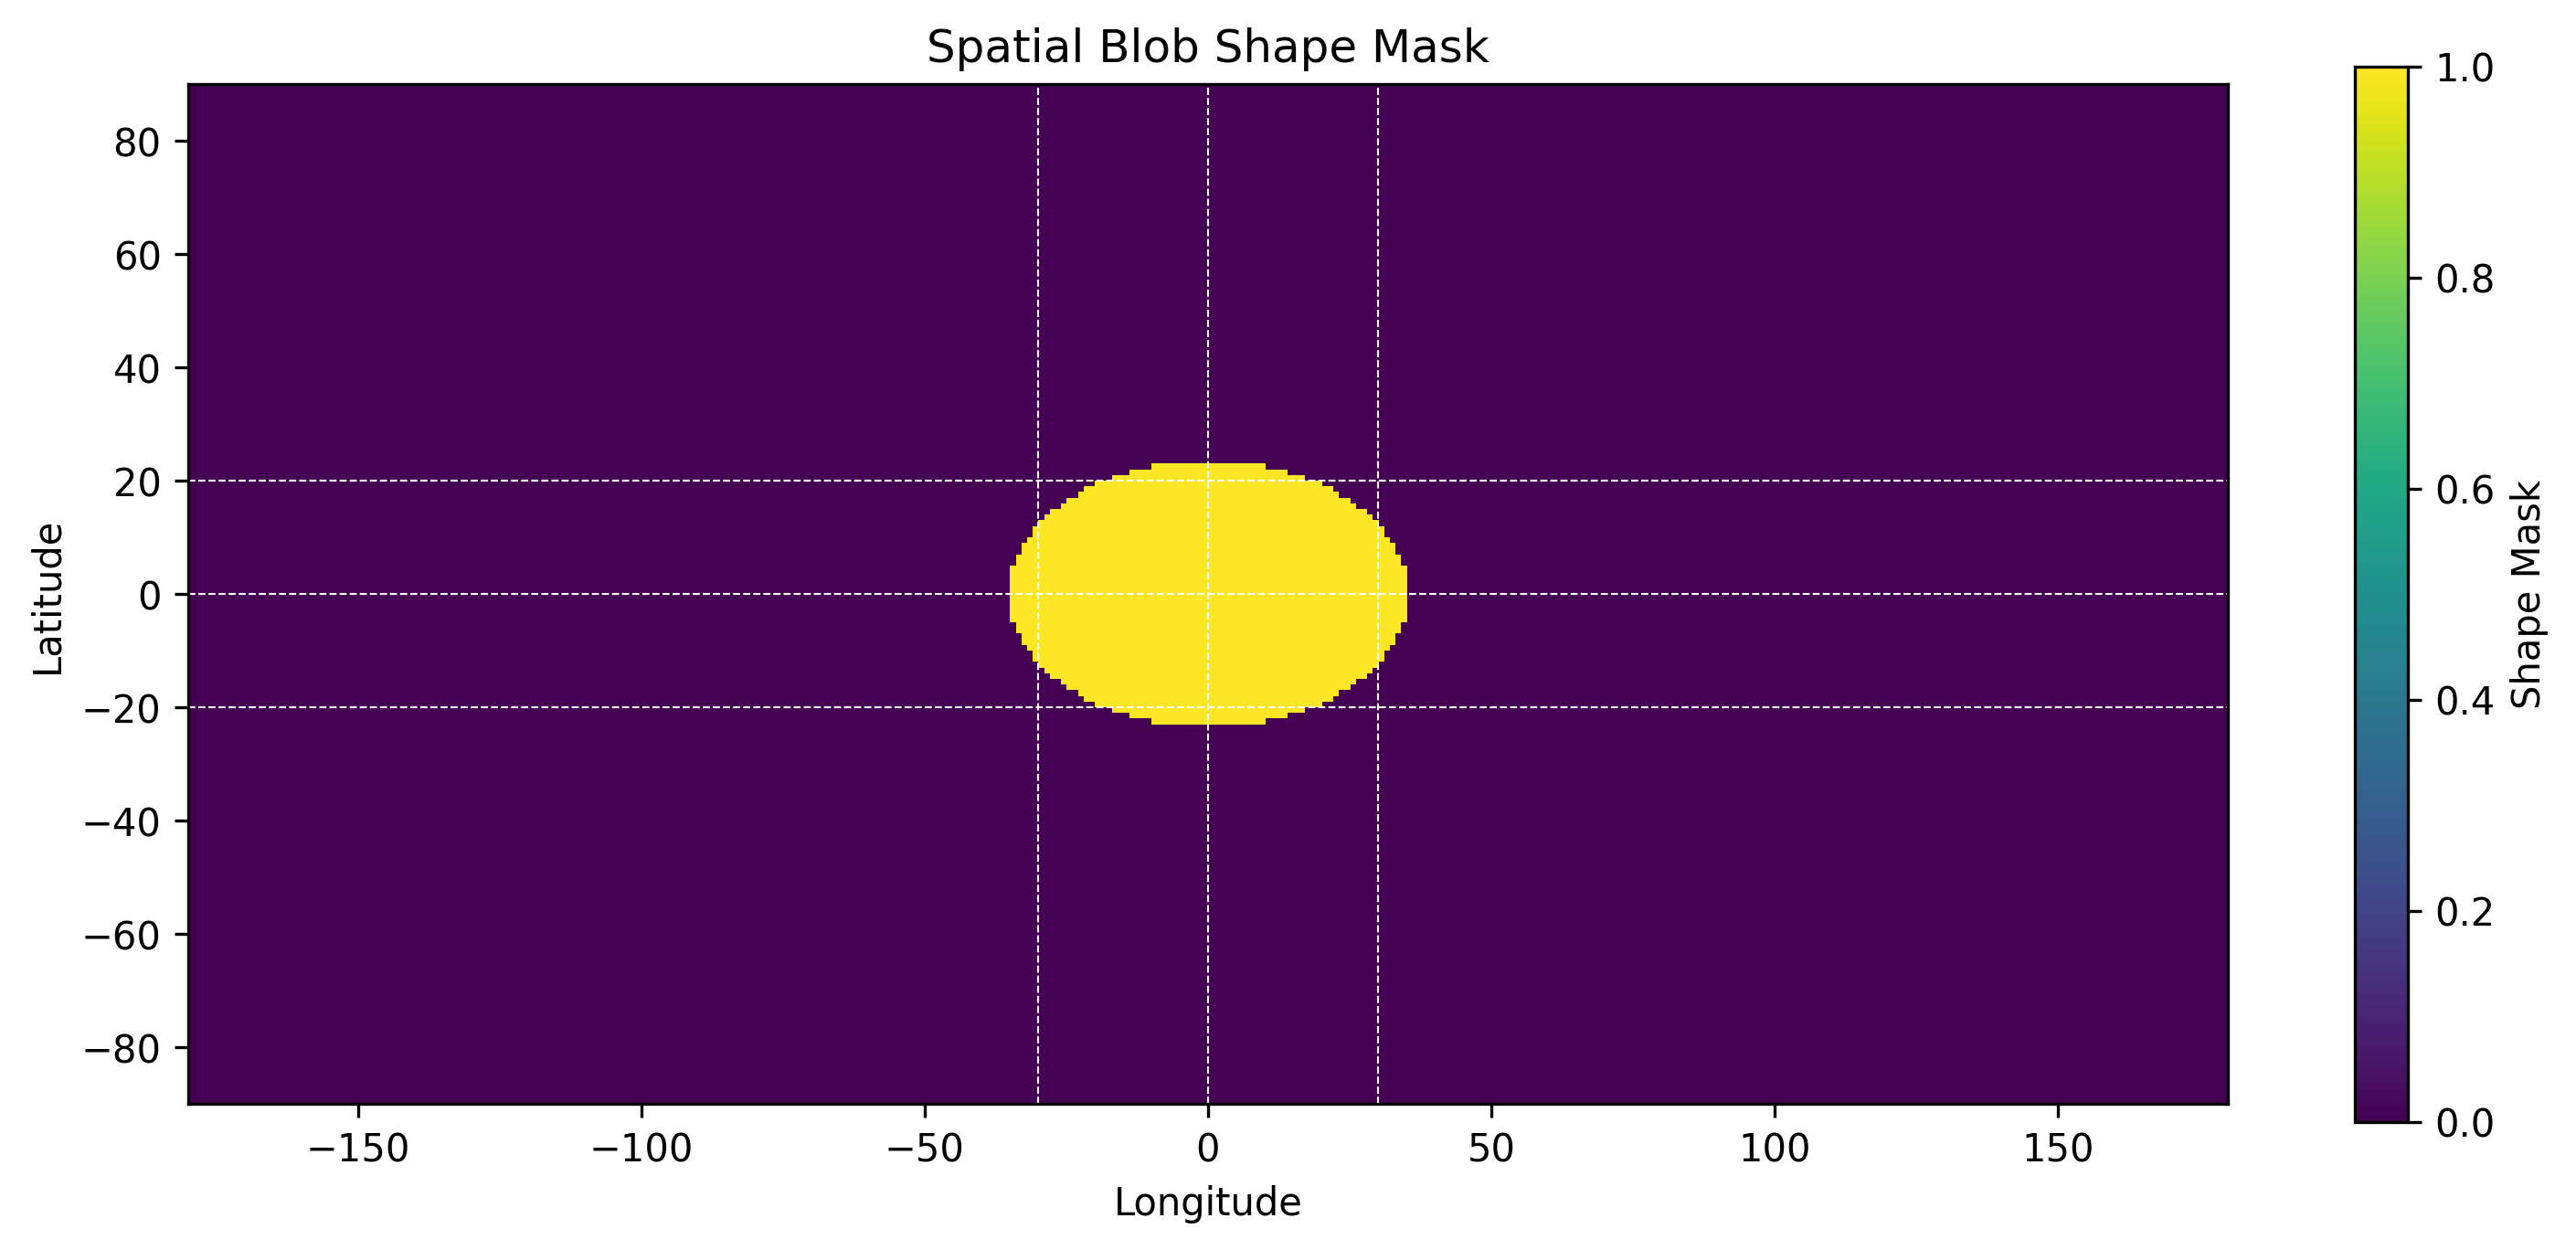

In [19]:
plt.imshow(
    shape_mask,
    extent=(-180, 180, -90, 90),
    origin='lower',
    cmap='viridis',
    )

plt.hlines(
    y=[center_lat, center_lat + sigma_lat, center_lat - sigma_lat],
    xmin=-180,
    xmax=180,
    color='white',
    linewidth=0.5,
    linestyle='--')

plt.vlines(
    x=[center_lon, center_lon + sigma_lon, center_lon - sigma_lon],
    ymin=-90,
    ymax=90,
    color='white',
    linewidth=0.5,
    linestyle='--')
plt.colorbar(label='Shape Mask')
plt.title('Spatial Blob Shape Mask')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [93]:
def make_shape(
        lats,
        lons,
    ) -> np.ndarray:
        """
        Generates a 2D spatial blob of eliptic shape. Given are the central latitude and longitude, as well as the
        extend of the blob in latitude and longitude. The function returns a mask of the same shape as the grid,
        where are values that are part of the blob are True, and all other values are False.

        Elliptic Formula:
        ((lat - center_lat) / sigma_lat)**2 + ((lon - center_lon) / sigma_lon)**2 <= 1
        """
        # Create coordinate combinations of all latitudes and longitudes
        # - handle longitude periodicity to ensure continuity at the dateline (global dataset!)
        extended_lons = np.concatenate([lons - 360, lons, lons + 360])
        # - create meshgrid for latitudes and extended longitudes
        lat_grid, lon_grid = np.meshgrid(lats, extended_lons, indexing='ij')

        # Calculate the mask for the elliptic shape on the longitude-extended grid
        shape_mask = ((lat_grid - center_lat) / ecc_lat)**2 + ((lon_grid - center_lon) / ecc_lon)**2 <= 1

        # add up contributions from periodic longitudes, shape_contribution is of shape (lat_size, lon_size)
        # - split shape_mask into three parts, one for each longitude section
        shape_mask = shape_mask.reshape(len(lats), 3, len(lons))
        # - transpose to have latitudes as first dimension
        shape_mask = shape_mask.transpose(1, 0, 2)
        # - if any of the three sections is True, then the point is part of the shape
        shape_mask = np.any(shape_mask, axis=0)

        return shape_mask

lat_size = 2
lon_size = 3

lats = np.linspace(-90, 90, lat_size)  # Example latitude grid
lons = np.linspace(-180, 180, lon_size)  # Example longitude grid
shape_mask = make_shape(lats, lons)

print("Shape mask generated with dimensions:", shape_mask.shape)

Shape mask generated with dimensions: (2, 3)


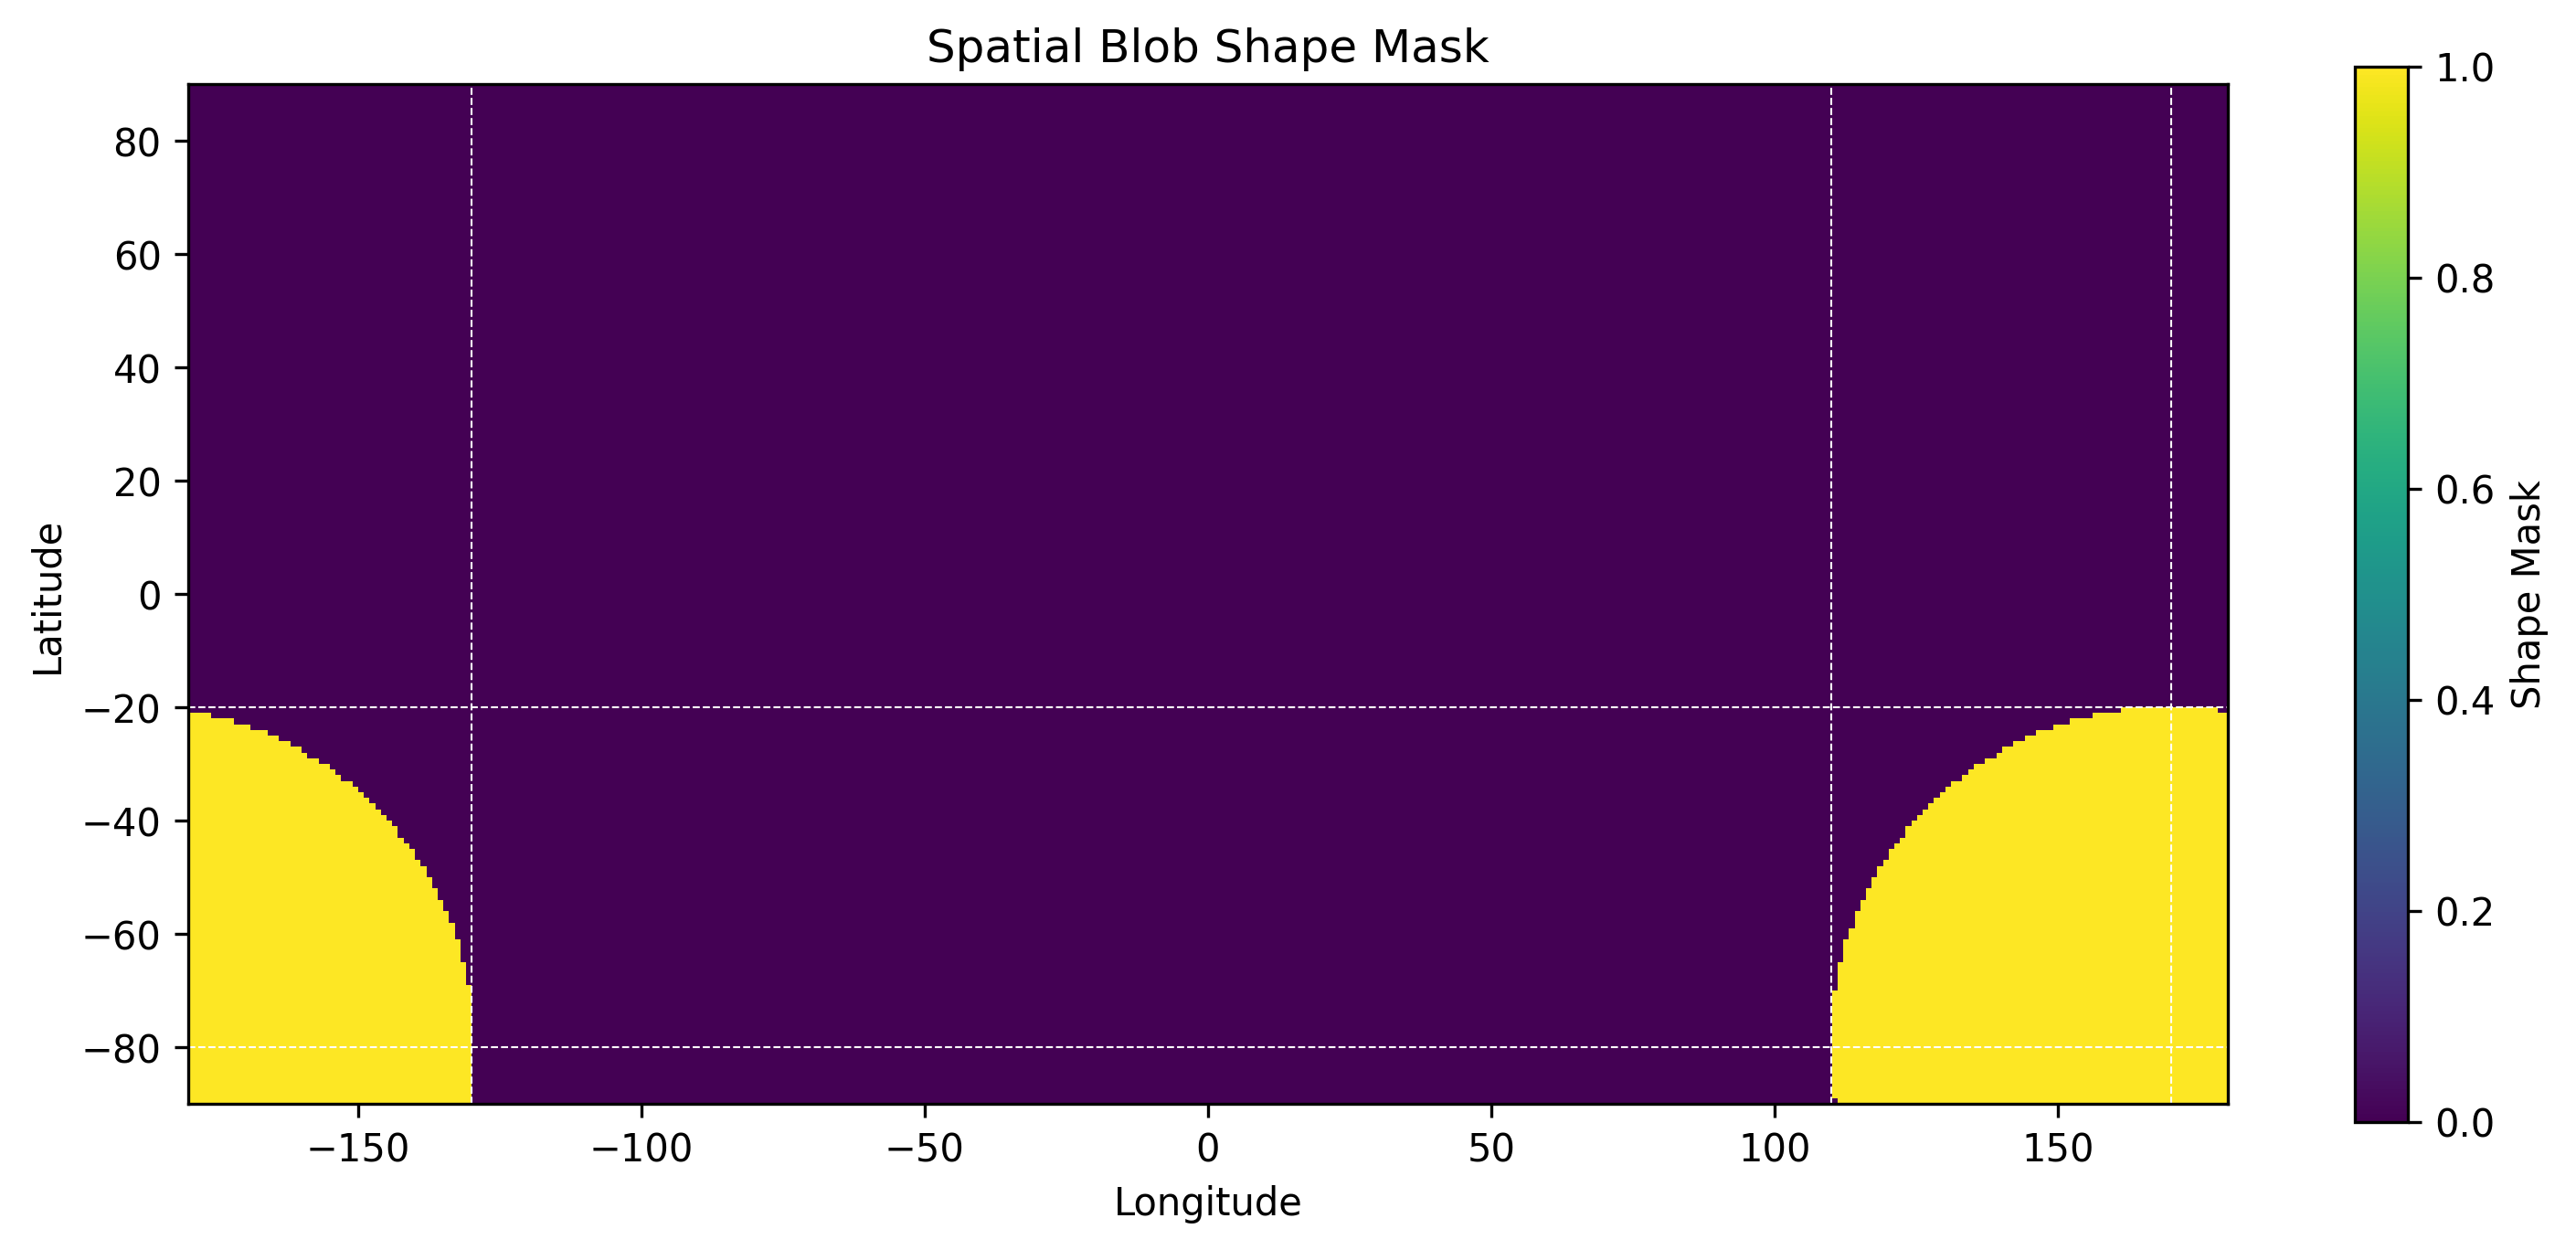

In [94]:
center_lat = -80.0  # Center latitude of the Gaussian blob
center_lon = 170.0  # Center longitude of the Gaussian blob
ecc_lat = 60.0  # Standard deviation in latitude
ecc_lon = 60.0  # Standard deviation in longitude

lat_size = 180
lon_size = 360

lats = np.linspace(-90, 90, lat_size)  # Example latitude grid
lons = np.linspace(-180, 180, lon_size)  # Example longitude grid
shape_mask = make_shape(lats, lons)


plt.imshow(
    shape_mask,
    extent=(-180, 180, -90, 90),
    origin='lower',
    cmap='viridis',
    )

lonp = -180 + (sigma_lon - 180 + center_lon) if center_lon + sigma_lon > 180 else center_lon + sigma_lon
lonm = 180 - (sigma_lon + 180 - center_lon) if center_lon - sigma_lon < -180 else center_lon - sigma_lon

plt.hlines(
    y=[center_lat, center_lat + sigma_lat, center_lat - sigma_lat],
    xmin=-180,
    xmax=180,
    color='white',
    linewidth=0.5,
    linestyle='--')

plt.vlines(
    x=[center_lon, lonp, lonm],
    ymin=-90,
    ymax=90,
    color='white',
    linewidth=0.5,
    linestyle='--')

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.colorbar(label='Shape Mask')
plt.title('Spatial Blob Shape Mask')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

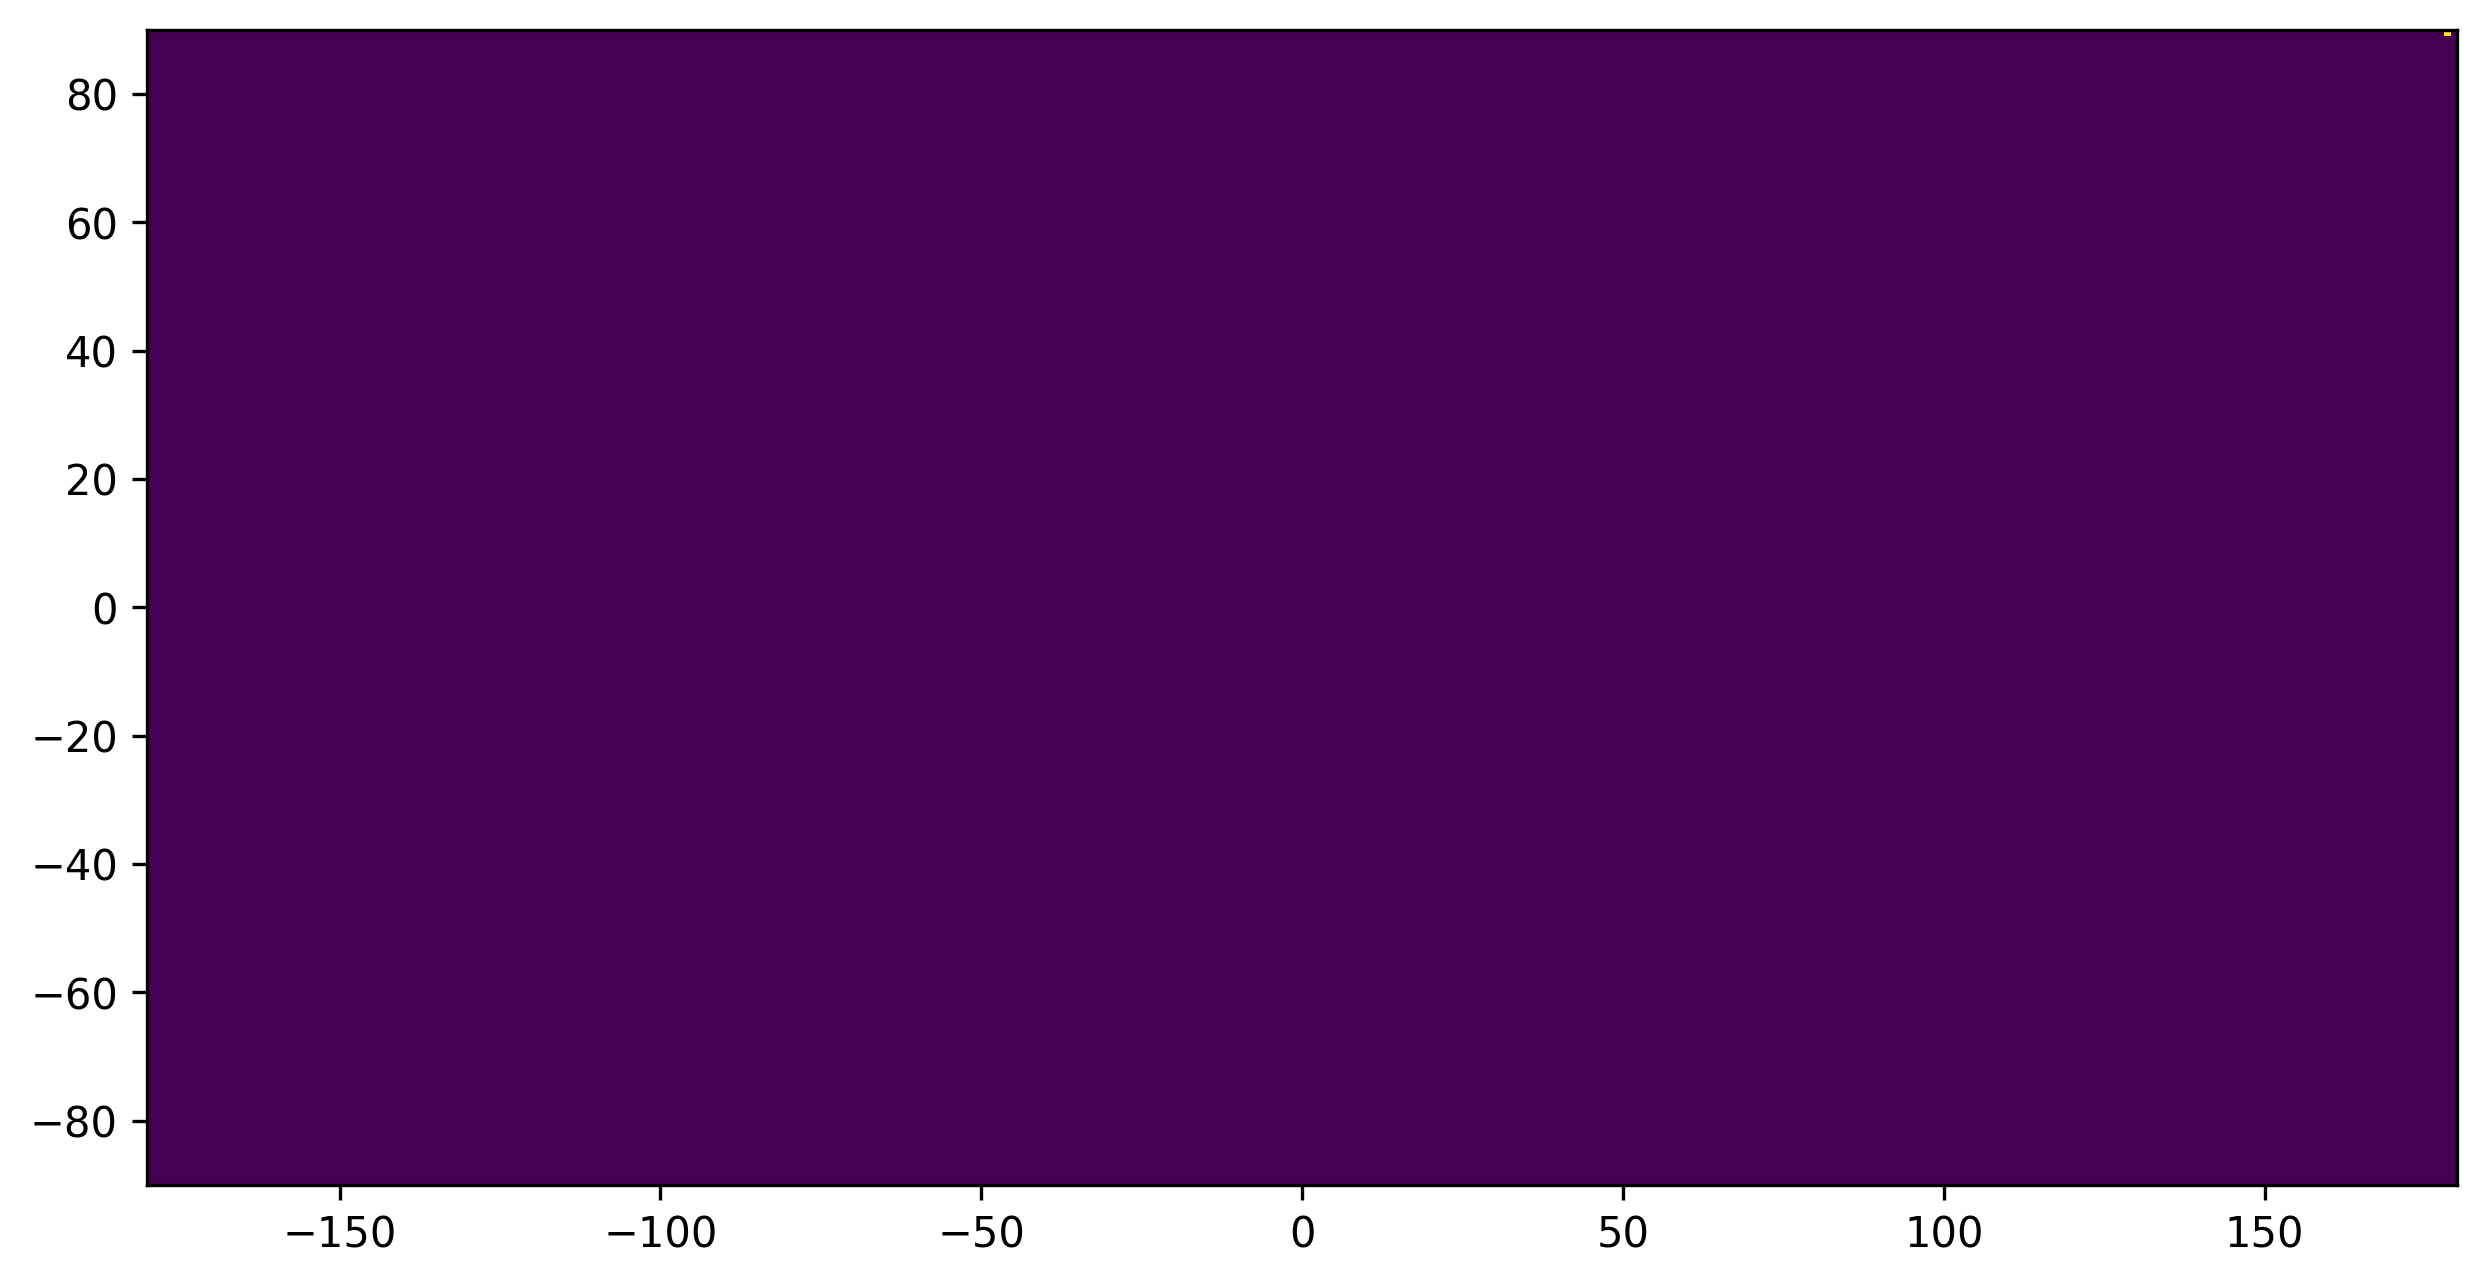

In [108]:
from ponds import BLOB

err = 3

# 1) setup variables
lat_size = 180
lon_size = 360

custom_center_lat = [-90, -88, 0, 42, 90]  # needs to be in range [-90, 90]
custom_center_lon = [-179, -110, 0, 63, 179]  # needs to be in range [-180, 180]
custom_ecc_lat = 0.75  # small eccentricity for a sharp blob (only one cell)
custom_ecc_lon = 0.75  # small eccentricity for a sharp blob (only one cell)

for center_lat in custom_center_lat:
    for center_lon in custom_center_lon:
        # 2) call function
        shape_method = BLOB(
            center_lat=center_lat,
            center_lon=center_lon,
            ecc_lat=custom_ecc_lat,
            ecc_lon=custom_ecc_lon,
        )
        mask_custom = shape_method.make_shape(
            lats=np.linspace(-90, 90, lat_size),
            lons=np.linspace(-180, 180, lon_size),
        )

        plt.imshow(
            mask_custom,
            extent=(-180, 180, -90, 90),
            origin='lower',
            cmap='viridis',
            )

        # 3) check results
        # - center_lat
        # -> ix of center_lat is 90 + custom_center_lat
        center_lat_exp = 90 + center_lat
        ix_lat_mean = np.mean(np.where(mask_custom.any(axis=1))[0])
        assert np.isclose(ix_lat_mean, center_lat_exp, atol=err), (
            f"Expected center_lat: {center_lat_exp}, got: {ix_lat_mean}"
        )
        # - center_lon
        # -> ix of center_lon is 180 + custom_center_lon
        center_lon_exp = 180 + center_lon
        ix_lon_mean = np.mean(np.where(mask_custom.any(axis=0))[0])
        assert np.isclose(ix_lon_mean, center_lon_exp, atol=err), (
            f"Expected center_lon: {center_lon_exp}, got: {ix_lon_mean}"
        )
